In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('../data/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [4]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [5]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [7]:
df.shape

(7043, 21)

In [8]:
df["TotalCharges"].isna().sum()

np.int64(0)

EDA Q - Do customers who churn have different monthly charges from customers who stay?

In [9]:
df.groupby("Churn")["MonthlyCharges"].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

In [10]:
df.groupby("Churn")["MonthlyCharges"].median()

Churn
No     64.425
Yes    79.650
Name: MonthlyCharges, dtype: float64

Looks like so far evidence supports my original hypothesis: customers who churned had higher monthly charges on average - about $13.18 higher

Q - How does the distribution of MonthlyCharges differ between customers who stayed and customers who churned?

MonthlyCharges → numerical

Churn → categorical (Yes / No)


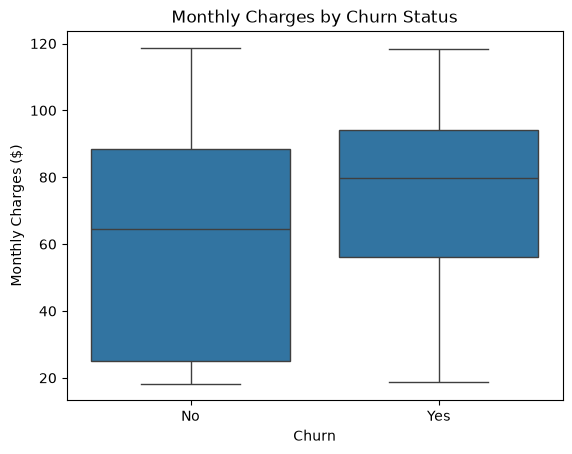

In [15]:
# first viz for numrical vs categorical is a box plot
sns.boxplot(data=df, x='Churn', y='MonthlyCharges')
plt.title('Monthly Charges by Churn Status')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges ($)')
plt.show()

If the distributions overlap heavily, MonthlyCharges alone probably can't cleanly separate churners from non-churners even if their averages differ.
A relationship can exist without one feature being sufficient for prediction.

My observations:

1. The box always contains the middle 50% of observations in that group, regardless of how tall it is.
A taller box does not mean it contains more customers.

It means the middle 50% covers a wider range of MonthlyCharges.

That range is the IQR=Q3-Q1

So if the No box is taller, I'd say:
Monthly charges have greater spread among the middle 50% of non-churners.

2. Median MonthlyCharges is higher for churners.
3. The two boxes/whiskers occupy a lot of the same MonthlyCharges territory. That tells us something important:
Higher monthly charges are associated with churn, but MonthlyCharges alone cannot reliably tell us whether an individual customer will churn.

Conclusion from EDA so far
Customers who churned had higher monthly charges on average and at the median than customers who stayed. However, the distributions overlap considerably, suggesting that monthly charges alone are unlikely to distinguish churners reliably.


Q - Calculate churn rate by SeniorCitizen

Ask - If we want to know whether senior customers churn more frequently, which comparison is more useful?

A: Number of senior vs non-senior customers who churned

or

B: Percentage/rate of senior vs non-senior customers who churned

In [16]:
# create temp numerical version fo the target
df['ChurnFlag'] = df['Churn'].map({
    'No': 0,
    'Yes': 1
})

In [18]:
df.groupby('SeniorCitizen')['ChurnFlag'].mean()

SeniorCitizen
0    0.236062
1    0.416813
Name: ChurnFlag, dtype: float64

when a binary variable is encoded as 0/1:
Its mean is the proportion of 1s.

Next compare he rate across two categories. use bar chart


In [20]:
senior_churn_rate = (
    df.groupby('SeniorCitizen')["ChurnFlag"]
    .mean()
    .reset_index()
)

senior_churn_rate

,SeniorCitizen,ChurnFlag
0,0,0.236062
1,1,0.416813


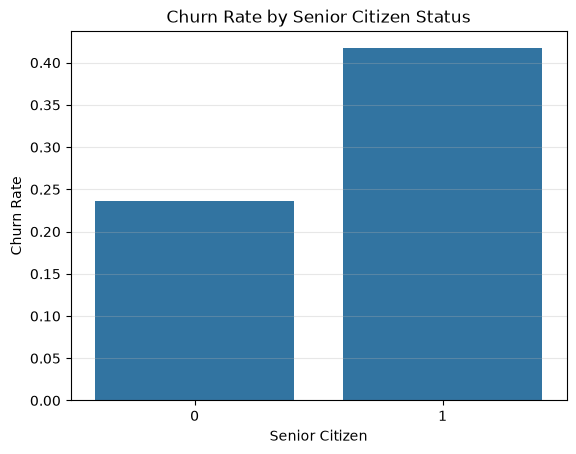

In [29]:
sns.barplot(
    data=senior_churn_rate,
    x="SeniorCitizen",
    y="ChurnFlag"
)
plt.title('Churn Rate by Senior Citizen Status')
plt.xlabel('Senior Citizen')
plt.ylabel('Churn Rate')
plt.grid(axis='y', alpha=0.3)
plt.show()

Observation
Senior citizens had a substantially higher churn rate about 42% compared with 24% among non-senior customers.

my third original hypothesis was:
Q - Customers with dependents might behave differently because of household financial considerations.

In [30]:
df.groupby('Dependents')['ChurnFlag'].mean()

Dependents
No     0.312791
Yes    0.154502
Name: ChurnFlag, dtype: float64

Customers without dependents had roughly twice the churn rate of customers with dependents in this dataset (31.3% vs. 15.5%).

Q - Does churn rate differ depending on the customer's contract type?

In [32]:
df.groupby('Contract')['ChurnFlag'].mean()*100

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: ChurnFlag, dtype: float64

Customers on month-to-month contracts had a much higher observed churn rate than customers on one- or two-year contracts. Churn rate decreased substantially for longer contract terms.

## there might be a confounding variable here
What if senior citizens are simply more likely to have month-to-month contracts?
Then part of the senior-citizen churn difference might actually be related to contract type.

This idea called a confounding variable.

Very simply:
We see a relationship between A and B, but another variable C may help explain that relationship.

In [40]:
# compare contract distributions within senior and non-senior customers.
pd.crosstab(
    df['SeniorCitizen'],
    df['Contract'],
    normalize='index'
) * 100

Contract,Month-to-month,One year,Two year
SeniorCitizen,,,
0,51.991188,21.742078,26.266734
1,70.665499,16.637478,12.697023


seniors are substantially more concentrated in the month-to-month category, and I already discovered that month-to-month customers have the highest churn rate.

ask a much better question:
If I compare seniors and non-seniors who have the SAME contract type, do seniors still churn at different rates?

In [42]:
df.groupby(['SeniorCitizen', 'Contract'])['ChurnFlag'].mean()*100

SeniorCitizen  Contract      
0              Month-to-month    39.569752
               One year          10.678098
               Two year           2.709677
1              Month-to-month    54.646840
               One year          15.263158
               Two year           4.137931
Name: ChurnFlag, dtype: float64

In [45]:
# investigate 
df.groupby('Churn')['tenure'].mean()

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64

In [46]:
df.groupby('Churn')['tenure'].median()

Churn
No     38.0
Yes    10.0
Name: tenure, dtype: float64

observation : Customers who churned tended to have substantially shorter tenure than customers who stayed. The median churned customer had been with the company for only 10 months, compared with 38 months among customers who stayed.


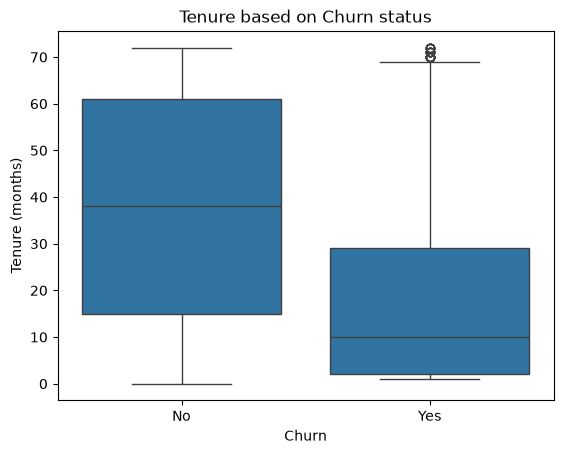

In [49]:
sns.boxplot(
    data=df,
    x='Churn',
    y='tenure'
)
plt.title('Tenure based on Churn status')
plt.xlabel('Churn')
plt.ylabel('Tenure (months)')
plt.show()

observation : Customers who churned generally had substantially shorter tenure than customers who stayed. However, the distributions overlap, and some long-tenure customers also churned, suggesting tenure alone cannot fully distinguish churners.

In [51]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn',
       'ChurnFlag'],
      dtype='str')

In [52]:
df['InternetService'].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

Q -Does churn rate differ between customers using DSL, Fiber optic, or no internet service?

In [63]:
pd.crosstab(
    df['InternetService'], df['Churn'],
    normalize='index'
) * 100

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


Fiber optic customers had the highest observed churn rate at about 42%, compared with 19% for DSL customers and 7% for customers without internet service.

Next q - Could Fiber optic customers also be paying more per month?

In [67]:
df.groupby('InternetService')['MonthlyCharges'].mean()

InternetService
DSL            58.102169
Fiber optic    91.500129
No             21.079194
Name: MonthlyCharges, dtype: float64

Fiber optic customers have the highest average monthly charge at about $91.50, compared with $58.10 for DSL and $21.08 for customers without internet service

Better question
Among Fiber optic customers specifically, do customers who churn pay more than customers who stay?

In [68]:
df.groupby(['InternetService', 'Churn'])["MonthlyCharges"].mean()

InternetService  Churn
DSL              No       60.212105
                 Yes      49.083224
Fiber optic      No       93.932379
                 Yes      88.126484
No               No       21.136058
                 Yes      20.368142
Name: MonthlyCharges, dtype: float64

In [69]:
pd.crosstab(
    df['Churn'], df['InternetService'],
    normalize='index'
) * 100

InternetService,DSL,Fiber optic,No
Churn,,,
No,37.920371,34.770004,27.309625
Yes,24.558587,69.395399,6.046014


Investigate TechSupport
How does churn rate differ among these three TechSupport groups?

In [74]:
df.groupby('TechSupport')['ChurnFlag'].mean()*100

TechSupport
No                     41.635474
No internet service     7.404980
Yes                    15.166341
Name: ChurnFlag, dtype: float64

Observation: Among customers with internet service, customers without TechSupport had a substantially higher observed churn rate than customers with TechSupport (41.6% vs. 15.2%).

Q For rows where InternetService is "No", what unique TechSupport values exist?

In [80]:
df.groupby('InternetService')['TechSupport'].unique()

InternetService
DSL                        [No, Yes]
Fiber optic                [No, Yes]
No             [No internet service]
Name: TechSupport, dtype: object

confirmed that "No internet service" in TechSupport isn't an independent customer choice. it is determined by InternetService.

Q- How does churn rate differ among customers with OnlineSecurity, without OnlineSecurity, and without internet service?

In [83]:
df.groupby('OnlineSecurity')['ChurnFlag'].mean()*100


OnlineSecurity
No                     41.766724
No internet service     7.404980
Yes                    14.611194
Name: ChurnFlag, dtype: float64

Customers with OnlineSecurity had a substantially lower observed churn rate (14.6%) than internet customers without OnlineSecurity (41.8%).

Repetitive EDa loop

In [84]:
service_features = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

In [85]:
for feature in service_features:
    print(f"\n ---Feature")
    print(df.groupby(feature)['ChurnFlag'].mean()*100)


 ---Feature
OnlineSecurity
No                     41.766724
No internet service     7.404980
Yes                    14.611194
Name: ChurnFlag, dtype: float64

 ---Feature
OnlineBackup
No                     39.928756
No internet service     7.404980
Yes                    21.531494
Name: ChurnFlag, dtype: float64

 ---Feature
DeviceProtection
No                     39.127625
No internet service     7.404980
Yes                    22.502064
Name: ChurnFlag, dtype: float64

 ---Feature
TechSupport
No                     41.635474
No internet service     7.404980
Yes                    15.166341
Name: ChurnFlag, dtype: float64

 ---Feature
StreamingTV
No                     33.523132
No internet service     7.404980
Yes                    30.070188
Name: ChurnFlag, dtype: float64

 ---Feature
StreamingMovies
No                     33.680431
No internet service     7.404980
Yes                    29.941435
Name: ChurnFlag, dtype: float64


## numerical feature relationships 

In [86]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

df[numerical_features].corr()

,tenure,MonthlyCharges,TotalCharges
tenure,1.000000,0.247900,0.826178
MonthlyCharges,0.247900,1.000000,0.651174
TotalCharges,0.826178,0.651174,1.000000


Visualize the strongest relationship

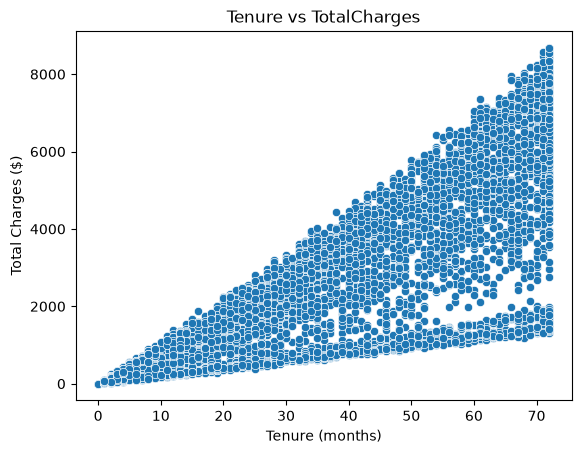

In [88]:
sns.scatterplot(
    data=df,
    x='tenure',
    y='TotalCharges'
)
plt.title('Tenure vs TotalCharges')
plt.xlabel('Tenure (months)')
plt.ylabel('Total Charges ($)')
plt.show()

As tenure increases, the spread of TotalCharges becomes much wider. So TotalCharges isn't determined by tenure alone. MonthlyCharges also matters.

modify chart by adding third variable in hue


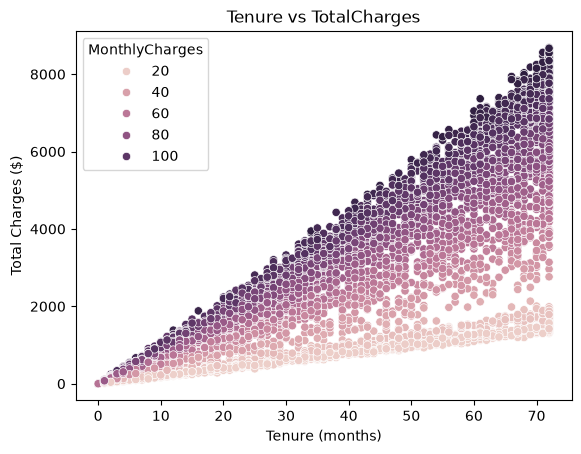

In [90]:
sns.scatterplot(
    data=df,
    hue='MonthlyCharges',
    x='tenure',
    y='TotalCharges'
)
plt.title('Tenure vs TotalCharges')
plt.xlabel('Tenure (months)')
plt.ylabel('Total Charges ($)')
plt.show()

TotalCharges tends to increase with both tenure and MonthlyCharges.

## EDA conclusion

1. Churned customers had higher MonthlyCharges overall, but this appears partly related to the large proportion of Fiber optic customers among churners.
2. Month-to-month customers had a 42.7% churn rate, compared with 11.3% for one-year and 2.8% for two-year contracts.
3. Churned customers generally had shorter tenure: median tenure was 10 months for churners versus 38 months for customers who stayed.
4. About 69.4% of churners were Fiber optic customers, and Fiber optic customers had a 41.9% churn rate.
5. Customers without TechSupport had a much higher churn rate (41.6%) than customers with TechSupport (15.2%).